# 06 · Multi-head BiGRU: results on held-out subjects

**Encoder** (`src/model.py`): 5 s windows of canonical 2D sagittal pose at 30 Hz (10 joints, pelvis-centred,
leg-length-scaled) + velocities + visibility flags + sin/cos of the 6 segment angles + the 6 geometric joint
angles with validity flags → input MLP → 2-layer BiGRU (128 per direction), plus a local conv branch
(0.3 s receptive field) feeding the per-frame heads.

**v1 → v2.** The first model (v1) regressed every output from time-pooled features. That shrank
symmetry towards 0 (the mostly-symmetric training population) and could not express a max − min ROM.
v2 adds **dense per-frame heads** and computes the stride outputs from them with the **same formulas as
the gold labels**:
- **events head** (per frame): heel-strike / toe-off, left / right → sub-frame event times
- **angle head** (per frame): the 6 sagittal joint angles
- **formulas** (`gaitdata.derive`): strides from the events → cadence, stride / step / stance / swing time,
  stance %, double support, stride-time variability; ROM and peak knee flexion per stride from the angle
  curves; Robinson SI of each from the per-side values
- **pooled heads** kept as auxiliary losses, for **speed** (leg lengths/s → m/s with the patient's leg length),
  and as a fallback when no complete stride is decoded
- **left/right mirror augmentation** (swap sides, flip the SI sign)

**v2 → v3.** The v2 angle head re-learned trigonometry and was 2–4° off even on clean pose, so ROM symmetry
(a ~3° left/right difference) was invisible. v3 makes the angle head a **gated skip**:
`gate × exact geometric angle + (1 − gate) × learned angle`, gate forced to 0 where a needed keypoint is
hidden: exact geometry on clean pose, a denoised estimate on noisy pose. A **local conv branch** lets the
event and angle heads use the immediate foot motion next to the BiGRU's global context.

**v3 → v4.** Event errors were small (3–5 ms) but *correlated with asymmetry*: random jitter of the same size
keeps the SI slope at 1.0, the model's own events gave 0.6. It had learned "the legs are half a cycle apart"
from a near-symmetric training population. v4 adds **synthetic asymmetry** (p = 0.5): one leg phase-shifted
by up to ±50 ms and its hip/knee/ankle excursions scaled ×0.8–1.25 by rigid segment rotations, with all
labels recomputed from the modified events and angles.

**Labels** are recomputed per window from the strides fully inside it (force-plate events for Fukuchi
treadmill, bias-corrected Zeni elsewhere). **Split**: subject-level; **Toronto is held out entirely**
(older adults, IMU capture). **Pose-noise augmentation** (`src/augment.py`) and every evaluation level
give all methods the identical noisy input (σ in leg lengths; 0.01 ≈ 8 mm).

*This project is a prototype and is not medical advice.*

In [1]:
import sys, json, warnings
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src"))
warnings.filterwarnings("ignore", category=RuntimeWarning)
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display
from analysis import *
style()
pd.set_option("display.width", 200, "display.max_columns", 40)
EV = ROOT / "outputs" / "eval" / "test"
MOD = ROOT / "outputs" / "models"
V4, PREV = "bigru_v4", "bigru_aug"
RUN = f"{V4}+derived"                    # the reported model: events + angle curves -> formulas
METHODS = [RUN, PREV, "classic", "mean"]
MLABEL = {RUN: "v4 (final)", PREV: "v1: pooled regression heads",
          "classic": "Classic pipeline", "mean": "Mean predictor", V4: "v4 pooled heads (auxiliary)",
          "bigru_v3+derived": "v3: no synthetic asymmetry", "bigru_v2+derived": "v2: no gated geometry / local branch",
          "bigru_v2_noswap+derived": "v2 without L/R mirror", "bigru_clean": "v1 trained on clean mocap"}
MCOL = {RUN: SERIES[0], PREV: SERIES[1], "classic": SERIES[2], "mean": MUTED, V4: SERIES[0]}
MSTY = {RUN: "-", PREV: "-", "classic": "-", "mean": "--"}
reg = pd.read_csv(EV / "regression.csv")
evs = pd.read_csv(EV / "events.csv")
angs = pd.read_csv(EV / "angles.csv")
sbins = pd.read_csv(EV / "symmetry_bins.csv")
P = pd.read_parquet(EV / "predictions.parquet")
TR1 = pd.read_csv(ROOT / "outputs" / "eval" / "test_trial" / "regression.csv").assign(protocol="one pass")
TR2 = pd.read_csv(ROOT / "outputs" / "eval" / "test_trial_twopass" / "regression.csv").assign(protocol="two passes")
LEVELS = sorted(reg.level.unique())
SI = ["SI_step_time", "SI_stance_time", "SI_swing_time", "SI_hip_rom", "SI_knee_rom", "SI_ankle_rom"]
UNIT = {"cadence": "steps/min", "stance_pct": "% cycle", "speed_ms": "m/s", "SI_step_time": "SI %",
        "SI_stance_time": "SI %", "SI_swing_time": "SI %", "SI_knee_rom": "SI %", "SI_hip_rom": "SI %",
        "SI_ankle_rom": "SI %", "knee_rom": "deg", "ankle_rom": "deg", "hip_rom": "deg",
        "peak_knee_flex": "deg", "double_support": "s", "stride_time": "s", "stride_time_cv": "%"}

## Training curves
Validation loss on held-out validation subjects with fixed noise (σ = 0.02); the best epoch is kept. v4's
training loss is higher by design (half its windows carry synthetic asymmetry); v2's angle loss used a
different smooth-L1 β and is not shown.

findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


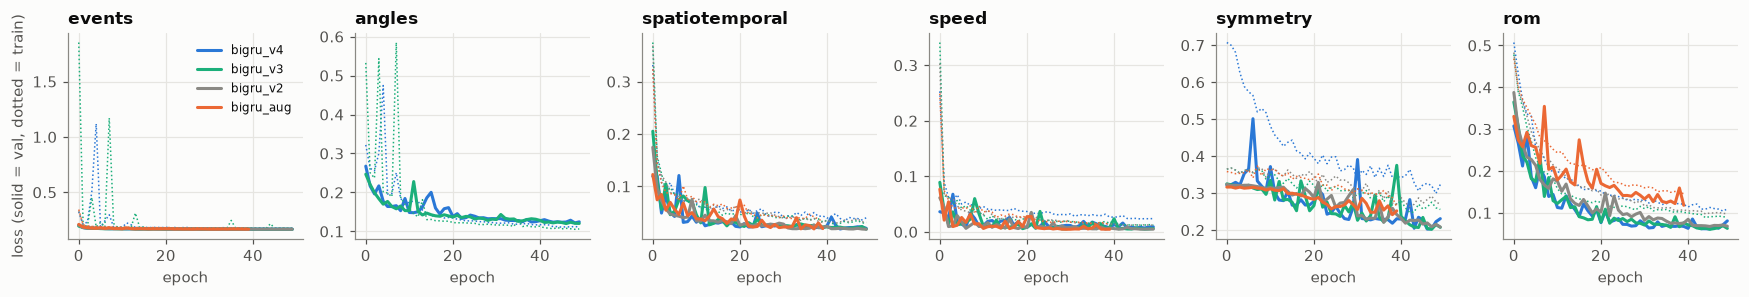

In [2]:
heads = ["events", "angles", "spatiotemporal", "speed", "symmetry", "rom"]
fig, axs = plt.subplots(1, len(heads), figsize=(16, 2.8), sharex=True)
for r, c in ((V4, SERIES[0]), ("bigru_v3", SERIES[2]), ("bigru_v2", MUTED), (PREV, SERIES[1])):
    h = pd.read_csv(MOD / r / "history.csv")
    for a, k in zip(axs, heads):
        if f"val_{k}" in h and not (k == "angles" and r == "bigru_v2"):
            a.plot(h.epoch, h[f"val_{k}"], color=c, label=r)
            a.plot(h.epoch, h[f"train_{k}"], color=c, lw=1, ls=":")
for a, k in zip(axs, heads): a.set_title(k); a.set_xlabel("epoch")
axs[0].set_ylabel("loss (solid = val, dotted = train)")
axs[0].legend(fontsize=8)
fig.tight_layout(); save(fig, "06_training_curves"); plt.show()

## Headline table
Mean absolute error per dataset on held-out subjects (per 5 s window), clean input (σ = 0) and realistic
video-pose noise (σ = 0.02). Best per row in bold.

In [3]:
core = ["cadence", "stride_time", "stance_pct", "double_support", "speed_ms", "SI_step_time", "SI_stance_time",
        "SI_knee_rom", "SI_ankle_rom", "hip_rom", "knee_rom", "ankle_rom", "peak_knee_flex", "stride_time_cv"]
T = (reg[reg.target.isin(core) & reg.level.isin([0, 0.02])]
     .pivot_table(index=["dataset", "target"], columns=["level", "method"], values="mae")
     .reindex(columns=METHODS, level=1))
T = T.reindex(pd.MultiIndex.from_product([DATASETS, core]), axis=0).dropna(how="all")
T.style.format("{:.3g}").apply(lambda r: ["font-weight: bold" if v == r[l].min() else "" for (l, m), v in r.items()], axis=1)

## Symmetry: is real asymmetry reported at its true size?
A low MAE on SI is easy: most people are near-symmetric, so predicting ~0 scores well. What matters for a
patient is whether a *large* asymmetry comes out large. Two checks: the slope of predicted vs gold SI
(1 = correct size, 0 = always the mean) and the error by size of the true asymmetry, with the average
amount by which |SI| is under-reported (negative = shrunk towards 0).

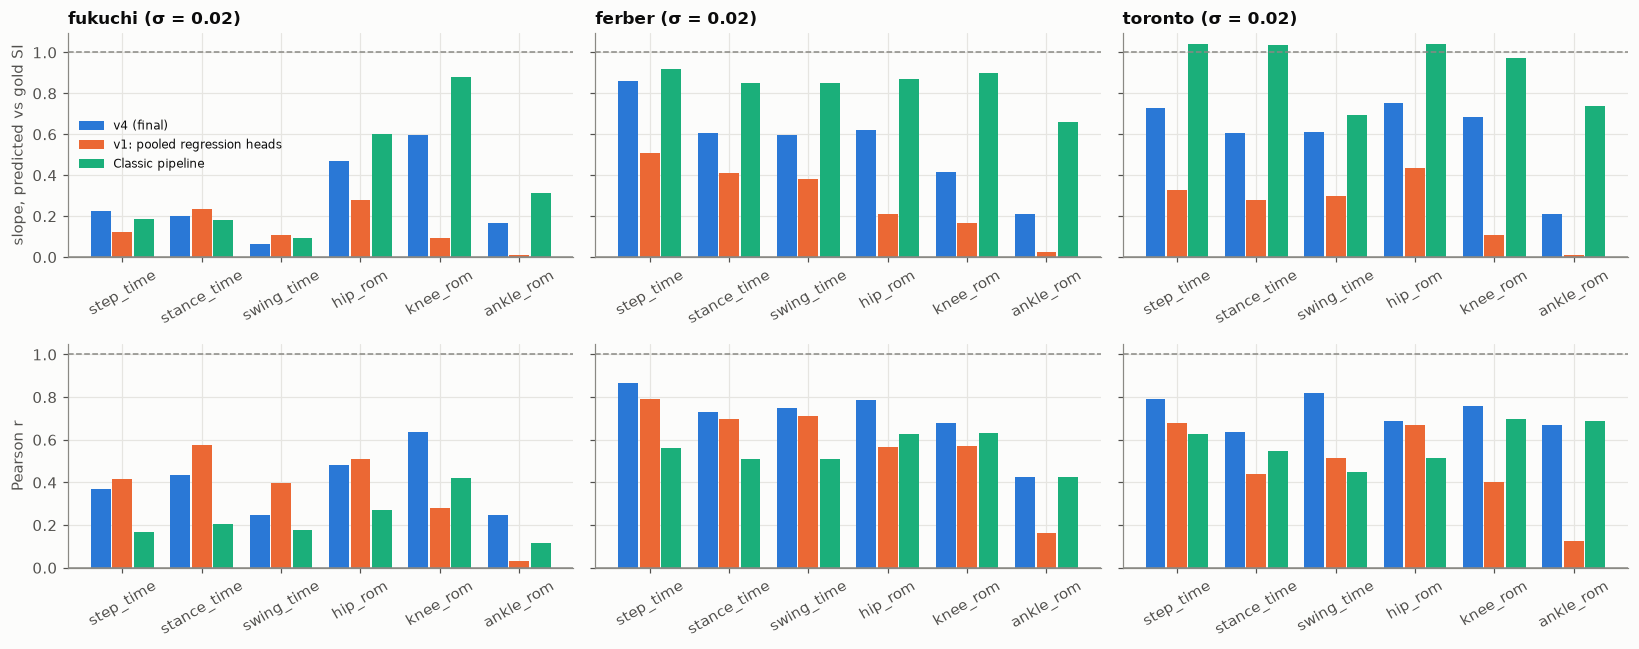

In [4]:
S = reg[reg.target.isin(SI) & (reg.level == 0.02) & reg.method.isin([RUN, PREV, "classic"])]
fig, axs = plt.subplots(2, len(DATASETS), figsize=(15, 6), sharey="row")
x = np.arange(len(SI))
for k, ds in enumerate(DATASETS):
    for j, m in enumerate([RUN, PREV, "classic"]):
        q = S[(S.dataset == ds) & (S.method == m)].set_index("target").reindex(SI)
        axs[0, k].bar(x + (j - 1) * 0.27, q.slope, width=0.25, color=MCOL[m], label=MLABEL[m])
        axs[1, k].bar(x + (j - 1) * 0.27, q.r, width=0.25, color=MCOL[m])
    for a in axs[:, k]:
        a.axhline(1, color=MUTED, lw=1, ls="--"); a.axhline(0, color=MUTED, lw=1)
        a.set_xticks(x, [s.replace("SI_", "") for s in SI], rotation=30)
    axs[0, k].set_title(f"{ds} (σ = 0.02)")
axs[0, 0].set_ylabel("slope, predicted vs gold SI"); axs[1, 0].set_ylabel("Pearson r")
axs[0, 0].legend(fontsize=8)
fig.tight_layout(); save(fig, "06_symmetry_slope"); plt.show()

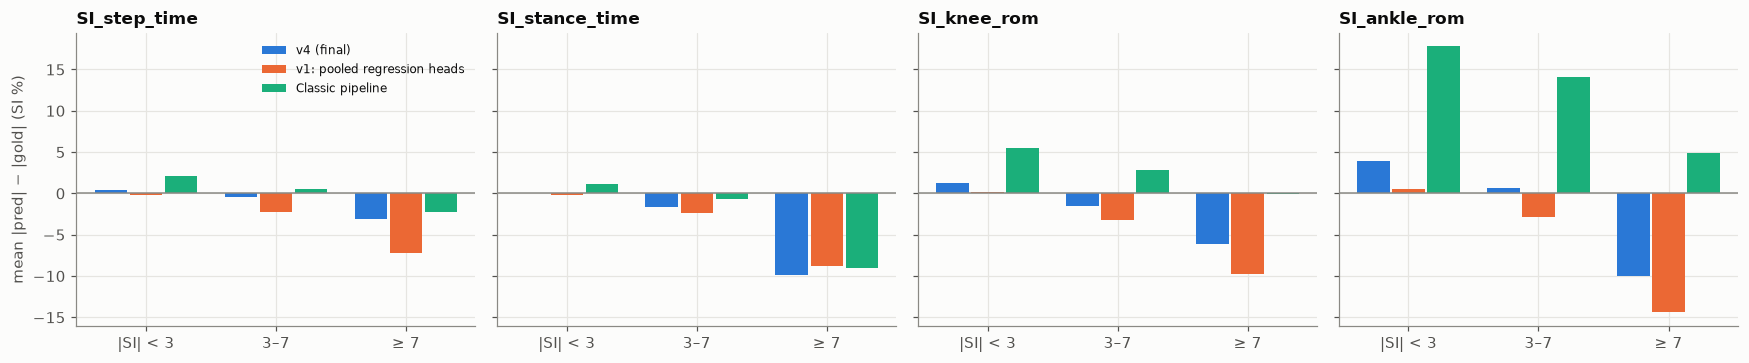

mae                                           mean_abs_shrink                                          
method                 bigru_aug bigru_v3+derived bigru_v4+derived classic       bigru_aug bigru_v3+derived bigru_v4+derived classic
target         abs_bin                                                                                                              
SI_ankle_rom   3-7          5.07             6.01             6.68   16.07           -1.77             1.58             2.09   11.98
               <3           2.88             6.40             6.49   21.36            1.18             5.23             5.12   20.15
               >=7         20.50            17.45            17.40   23.12          -18.28           -14.85           -14.01    4.87
SI_hip_rom     3-7          3.50             3.66             4.04    7.13           -2.46            -1.32            -0.49    3.48
               <3           2.27             2.52             2.91    6.81            0.63             1.01             1.60    5.50
               >=7          8.24             6.18             5.09    8.36           -7.92            -5.79            -4.17    0.35
SI_knee_rom    3-7          5.25             3.44             3.98    7.26           -3.13            -2.00            -1.53    2.90
               <3           2.11             2.68             3.18    7.83            0.49             1.35             1.89    6.63
               >=7         11.36             7.16             6.39    7.82          -10.22            -6.17            -5.15   -0.01
SI_stance_time 3-7          3.02             2.04             2.36    2.98           -2.50            -1.64            -1.22   -0.28
               <3           1.56             1.09             1.36    2.66            0.20             0.05             0.34    1.60
               >=7          8.93             9.05            10.14    9.84           -8.72            -8.59            -9.32   -7.13
SI_step_time   3-7          2.77             2.11             2.23    4.52           -2.64            -1.57            -0.49    1.47
               <3           1.27             1.44             1.74    3.44           -0.26             0.10             0.57    2.18
               >=7          6.93             4.94             4.22    5.72           -6.51            -4.33            -2.72   -2.48
SI_swing_time  3-7          3.68             2.11             2.31    3.93           -2.30            -1.70            -1.26   -0.02
               <3           2.07             1.35             1.83    3.79            0.58             0.23             0.69    2.58
               >=7          9.20             8.60             9.15   10.08           -9.07            -7.97            -8.29   -6.21

In [5]:
B = sbins[(sbins.level == 0.02) & sbins.method.isin([RUN, PREV, "classic"])]
fig, axs = plt.subplots(1, 4, figsize=(16, 3.4), sharey=True)
for a, t in zip(axs, ["SI_step_time", "SI_stance_time", "SI_knee_rom", "SI_ankle_rom"]):
    for j, m in enumerate([RUN, PREV, "classic"]):
        q = B[(B.target == t) & (B.method == m)].groupby("abs_bin").apply(
            lambda g: np.average(g.mean_abs_shrink, weights=g.n)).reindex(["<3", "3-7", ">=7"])
        a.bar(np.arange(3) + (j - 1) * 0.27, q, width=0.25, color=MCOL[m], label=MLABEL[m])
    a.axhline(0, color=MUTED, lw=1); a.set_xticks(range(3), ["|SI| < 3", "3–7", "≥ 7"]); a.set_title(t)
axs[0].set_ylabel("mean |pred| − |gold| (SI %)"); axs[0].legend(fontsize=8)
fig.tight_layout(); save(fig, "06_symmetry_shrinkage"); plt.show()
(sbins[(sbins.level == 0.02) & sbins.method.isin([RUN, "bigru_v3+derived", PREV, "classic"])]
 .pivot_table(index=["target", "abs_bin"], columns=["method"], values=["mae", "mean_abs_shrink"], aggfunc="mean")
 .round(2))

## How each method degrades with pose noise
On clean mocap the classic pipeline computes the labels with their own formulas, so it is hard to beat; the
learned model has to earn its place as the input starts to look like video pose. Dashed = mean predictor.

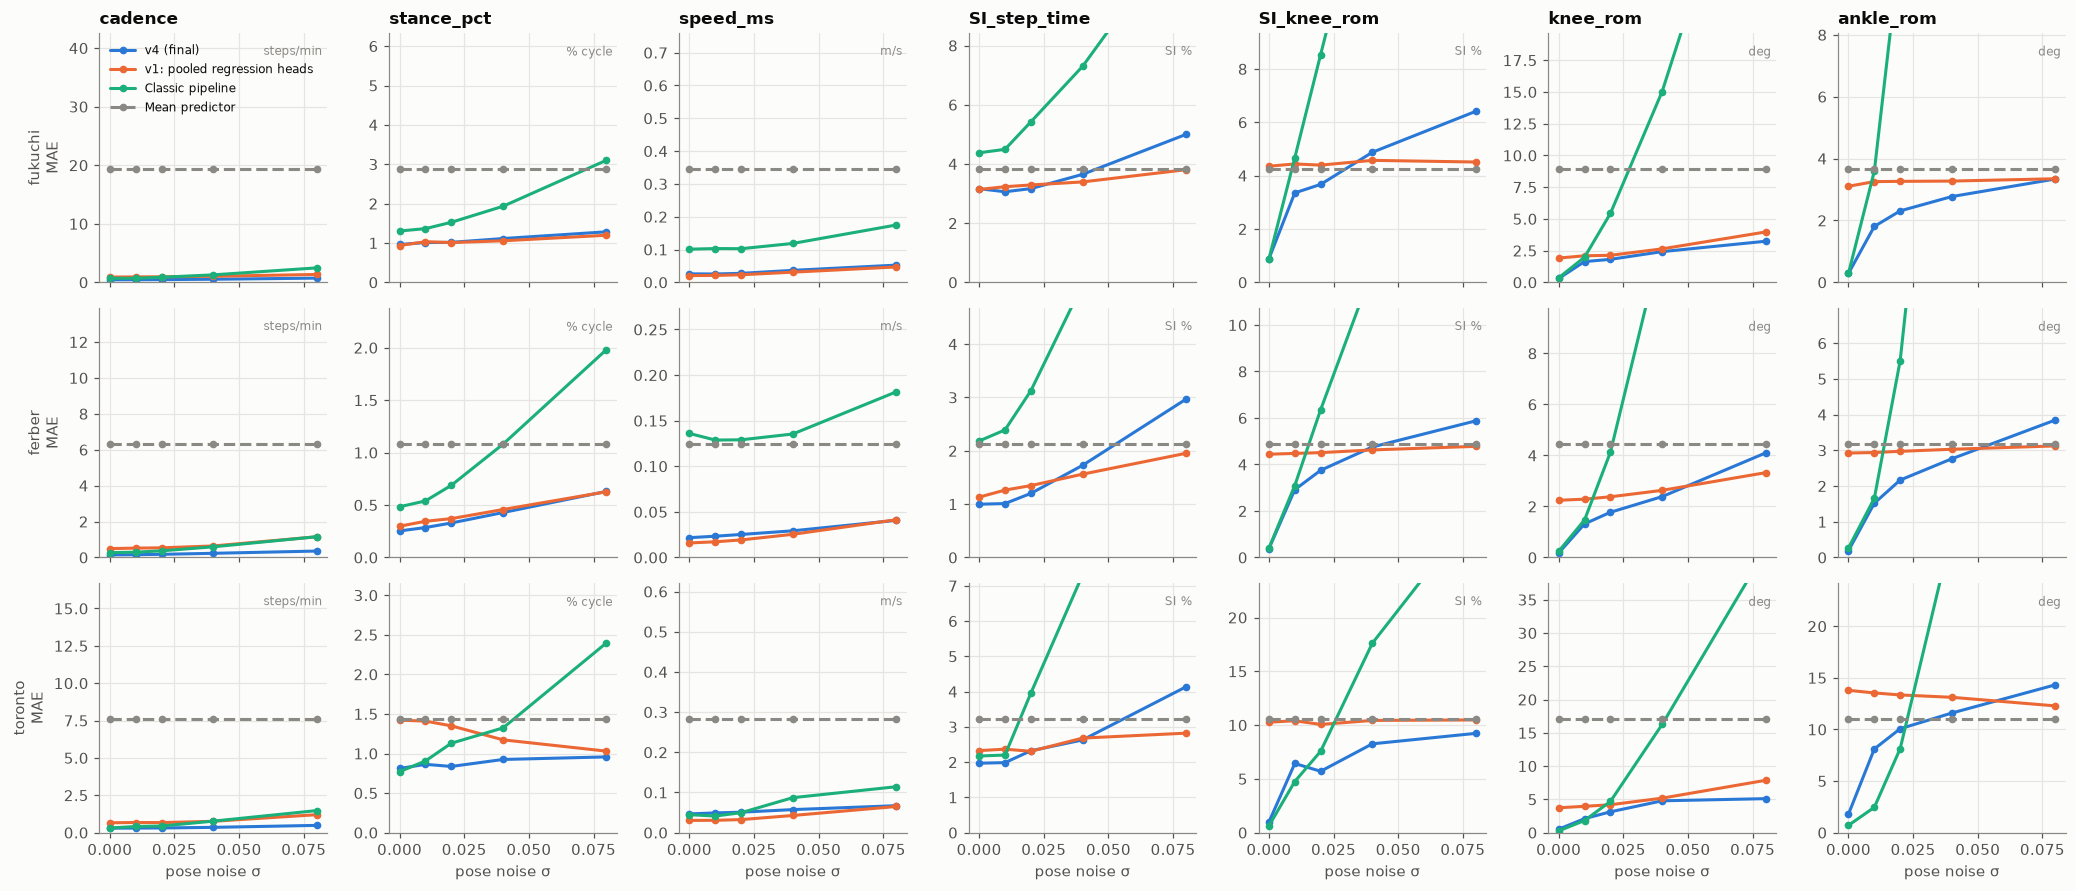

In [6]:
targets = ["cadence", "stance_pct", "speed_ms", "SI_step_time", "SI_knee_rom", "knee_rom", "ankle_rom"]
fig, axs = plt.subplots(len(DATASETS), len(targets), figsize=(19, 8.2), sharex=True)
for i, ds in enumerate(DATASETS):
    for k, t in enumerate(targets):
        a = axs[i, k]
        for m in METHODS:
            g = reg[(reg.dataset == ds) & (reg.target == t) & (reg.method == m)].sort_values("level")
            a.plot(g.level, g.mae, color=MCOL[m], ls=MSTY[m], marker="o", ms=4, label=MLABEL[m])
        a.set_ylim(0, 2.2 * reg[(reg.dataset == ds) & (reg.target == t) & (reg.method == "mean")].mae.max())
        if i == 0: a.set_title(t)
        if k == 0: a.set_ylabel(f"{ds}\nMAE")
        if i == len(DATASETS) - 1: a.set_xlabel("pose noise σ")
        a.text(0.98, 0.95, UNIT.get(t, ""), transform=a.transAxes, ha="right", va="top", color=MUTED, fontsize=8)
axs[0, 0].legend(fontsize=8, loc="upper left")
fig.tight_layout(); save(fig, "06_degradation"); plt.show()

## Joint-angle curves (angle head)
RMSE of the per-frame angles over the whole window, against the clean mocap angles. The classic curve is
the angle formula on the gap-filled, 6 Hz low-passed noisy input; v2 is the ungated angle head.

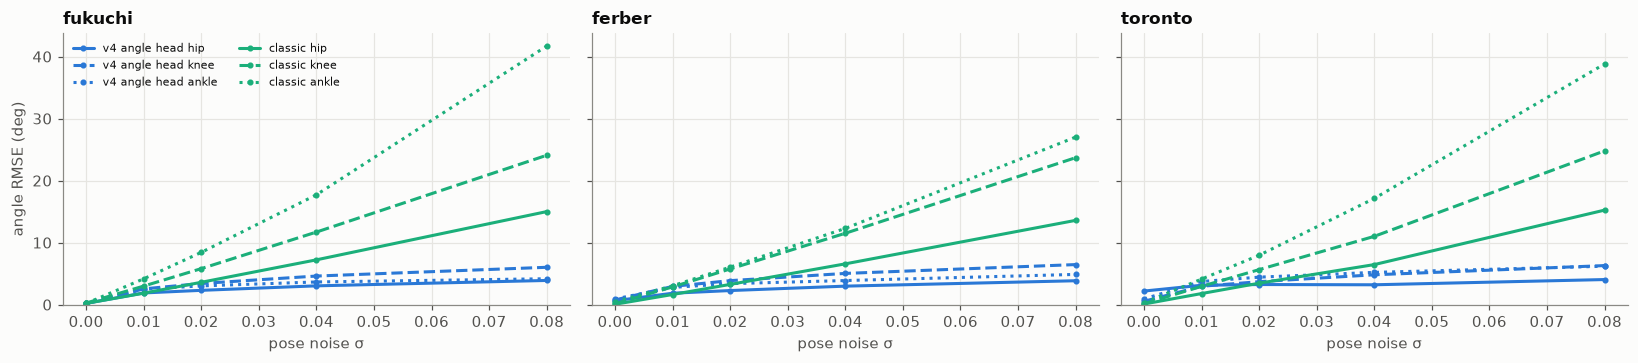

L_hip                    L_knee                   L_ankle                     R_hip                    R_knee                   R_ankle                 
method        bigru_v2 bigru_v4 classic bigru_v2 bigru_v4 classic bigru_v2 bigru_v4 classic bigru_v2 bigru_v4 classic bigru_v2 bigru_v4 classic bigru_v2 bigru_v4 classic
dataset level                                                                                                                                                            
ferber  0.00      1.67     0.69    0.06     2.95     1.26    0.16     3.11     1.27    0.27     1.69     0.57    0.06     2.29     0.25    0.17     2.65     0.57    0.66
        0.01      1.89     1.87    1.65     3.47     3.21    2.93     3.28     3.00    3.07     1.92     1.81    1.62     2.83     2.67    2.78     2.85     2.55    3.01
        0.02      2.30     2.27    3.23     4.14     4.12    5.79     3.53     3.59    6.08     2.32     2.27    3.29     3.58     3.62    5.73     3.15     3.18    6.02
        0.04      3.01     2.97    6.56     5.33     5.30   11.59     4.05     4.03   12.33     3.02     2.99    6.59     4.75     4.77   11.42     3.75     3.74   12.26
        0.08      3.88     3.82   13.46     6.68     6.66   23.50     5.13     5.03   26.99     3.94     3.89   13.72     6.05     6.26   23.89     4.74     4.72   27.03
fukuchi 0.00      2.25     0.24    0.21     2.38     0.15    0.27     2.52     0.22    0.19     1.95     0.18    0.20     2.66     0.15    0.26     2.40     0.16    0.21
        0.01      2.49     2.15    1.92     2.96     2.61    3.12     2.90     2.47    4.25     2.11     1.62    1.78     2.97     2.48    2.87     2.63     2.51    4.08
        0.02      2.85     2.53    3.64     3.74     3.50    5.85     3.36     3.07    8.48     2.38     2.09    3.57     3.50     3.32    5.76     3.02     2.98    8.38
        0.04      3.58     3.32    7.22     5.01     4.81   11.75     4.04     3.82   17.79     2.99     2.74    7.23     4.67     4.41   11.65     3.56     3.50   17.63
        0.08      4.30     4.14   14.80     6.17     6.27   24.02     4.43     4.30   41.20     3.74     3.66   15.21     6.06     5.78   24.15     4.01     4.05   42.19
toronto 0.00      2.71     2.06    0.10     2.73     0.53    0.14     3.99     0.97    0.34     3.62     2.32    0.10     2.63     0.54    0.15     3.82     0.88    0.27
        0.01      2.65     2.88    1.74     3.40     2.93    2.98     4.29     3.87    4.00     3.53     3.37    1.84     3.13     2.99    2.92     4.08     3.59    4.23
        0.02      2.83     2.88    3.53     3.77     3.57    5.68     4.58     4.64    8.12     3.70     3.61    3.39     3.51     3.84    5.60     4.25     4.23    7.80
        0.04      2.68     2.79    6.40     4.60     4.54   10.64     5.39     5.46   16.11     3.65     3.61    6.52     4.68     5.08   11.38     4.75     4.95   18.13
        0.08      3.66     3.76   15.46     6.05     6.35   24.86     5.97     6.38   38.98     4.48     4.33   15.02     5.95     6.24   24.73     5.42     6.00   38.62

In [7]:
J6 = ["L_hip", "L_knee", "L_ankle"]
fig, axs = plt.subplots(1, len(DATASETS), figsize=(15, 3.4), sharey=True)
for a, ds in zip(axs, DATASETS):
    for m, c in ((V4, SERIES[0]), ("classic", SERIES[2])):
        for j, ls in zip(J6, ("-", "--", ":")):
            g = angs[(angs.dataset == ds) & (angs.method == m)].sort_values("level")
            a.plot(g.level, (g[j] + g["R" + j[1:]]) / 2, color=c, ls=ls, marker="o", ms=3,
                   label=f"{'v4 angle head' if m == V4 else 'classic'} {j[2:]}")
    a.set_title(ds); a.set_xlabel("pose noise σ"); a.set_ylim(bottom=0)
axs[0].set_ylabel("angle RMSE (deg)"); axs[0].legend(fontsize=7, ncol=2)
fig.tight_layout(); save(fig, "06_angle_rmse"); plt.show()
angs[angs.method.isin([V4, "bigru_v2", "classic"])].set_index(["dataset", "level", "method"]).drop(columns="n").round(2).unstack("method")

## Gait events
Detection F1 within ±100 ms and timing error against the labels; events within 0.2 s of a window edge excluded.

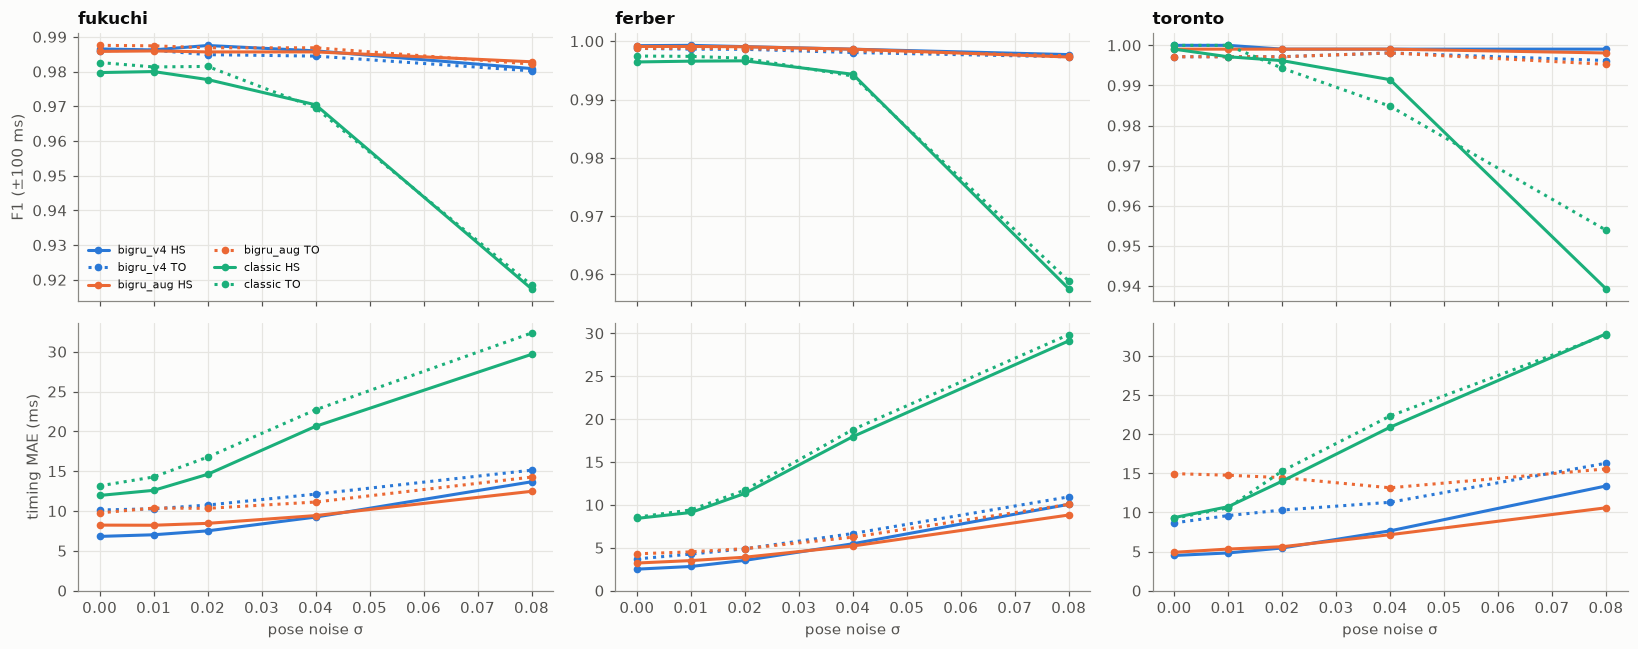

bias_ms                                                    f1                                                mae_ms                                            
level              0.00                       0.02                       0.00                       0.02                       0.00                       0.02                 
method        bigru_aug bigru_v4 classic bigru_aug bigru_v4 classic bigru_aug bigru_v4 classic bigru_aug bigru_v4 classic bigru_aug bigru_v4 classic bigru_aug bigru_v4 classic
dataset event                                                                                                                                                                  
ferber  HS        0.562   -0.684   0.439     0.945   -0.735   1.030     0.999    0.999   0.996     0.999    0.999   0.997     3.219    2.504   8.424     3.897    3.528  11.336
        TO       -0.658   -1.248  -2.224    -0.919   -1.684  -2.847     0.999    0.999   0.997     0.999    0.999   0.997     4.293    3.698   8.563     4.896    4.879  11.722
fukuchi HS       -2.956   -0.259   0.383    -2.376   -1.162   1.052     0.986    0.987   0.980     0.986    0.988   0.978     8.227    6.810  11.953     8.448    7.508  14.606
        TO       -3.502   -3.883  -3.451    -3.930   -3.418  -3.713     0.988    0.986   0.983     0.987    0.985   0.981     9.760   10.126  13.159    10.336   10.747  16.763
toronto HS        0.047    2.220   4.564    -0.248    1.394   5.523     0.999    1.000   0.999     0.999    0.999   0.996     4.902    4.498   9.343     5.615    5.454  14.001
        TO      -14.641   -6.493  -2.237   -13.858   -7.448  -4.794     0.997    0.997   1.000     0.997    0.997   0.994    14.967    8.663   9.244    14.451   10.308  15.295

In [8]:
E = evs[evs.method.isin([V4, PREV, "classic"])]
EC = {V4: SERIES[0], PREV: SERIES[1], "classic": SERIES[2]}
fig, axs = plt.subplots(2, len(DATASETS), figsize=(15, 6), sharex=True)
for k, ds in enumerate(DATASETS):
    for m in EC:
        for ev, ls in (("HS", "-"), ("TO", ":")):
            g = E[(E.dataset == ds) & (E.method == m) & (E.event == ev)].sort_values("level")
            axs[0, k].plot(g.level, g.f1, color=EC[m], ls=ls, marker="o", ms=4, label=f"{m} {ev}")
            axs[1, k].plot(g.level, g.mae_ms, color=EC[m], ls=ls, marker="o", ms=4)
    axs[0, k].set_title(ds); axs[1, k].set_xlabel("pose noise σ"); axs[1, k].set_ylim(bottom=0)
axs[0, 0].set_ylabel("F1 (±100 ms)"); axs[1, 0].set_ylabel("timing MAE (ms)")
axs[0, 0].legend(fontsize=7, ncol=2)
fig.tight_layout(); save(fig, "06_events"); plt.show()
E[E.level.isin([0, 0.02])].pivot_table(index=["dataset", "event"], columns=["level", "method"],
                                       values=["f1", "mae_ms", "bias_ms"]).round(3)

## Per recording: one output per video, and the two-pass protocol
A physio films more than 5 s. Here each test trial gets **one** noise draw over its whole length (fixed far leg,
keypoint offsets, scale and tilt, as in one real video), every window's strides are pooled, and the outputs are
computed over all strides of the trial (30 s treadmill trials ≈ 50 strides). Averaging removes random error but
not systematic shrinkage. **Two passes** = walk across and back: each leg is measured from the pass in which it
is nearest the camera, so no left/right comparison pits a near leg against an occluded far leg.

In [9]:
tg = ["SI_step_time", "SI_stance_time", "SI_hip_rom", "SI_knee_rom", "SI_ankle_rom", "knee_rom", "ankle_rom",
      "cadence", "stance_pct", "speed_ms"]
TR = pd.concat([TR1, TR2])
TR = TR[TR.target.isin(tg) & (TR.level == 0.02) & TR.method.isin([RUN, "bigru_v3+derived", "classic", "mean"])]
TR = TR[~((TR.method == "mean") & (TR.protocol == "two passes"))]
TR.assign(method=TR.method.map(lambda m: MLABEL.get(m, m))).pivot_table(
    index=["target", "dataset"], columns=["protocol", "method"], values=["mae", "slope"]).round(2)

mae                                                                                                                        slope                 \
protocol                       one pass                                                            two passes                                               one pass                  
method                 Classic pipeline Mean predictor v3: no synthetic asymmetry v4 (final) Classic pipeline v3: no synthetic asymmetry v4 (final) Classic pipeline Mean predictor   
target         dataset                                                                                                                                                                
SI_ankle_rom   ferber             15.71          11.33                       9.57       9.21             8.52                      10.31      10.27             0.68           0.00   
               fukuchi            27.31           8.93                       8.55       9.64            15.98                      10.41      10.98             0.41          -0.00   
               toronto            22.02          29.50                      25.78      24.47            14.96                      25.39      24.77             0.69           0.00   
SI_hip_rom     ferber              4.52           4.12                       2.76       2.55             3.46                       3.19       2.88             0.92          -0.00   
               fukuchi             8.04           2.71                       2.88       3.19             5.56                       3.40       3.26             1.00          -0.00   
               toronto             6.69           3.90                       4.13       4.27             5.02                       4.47       4.21             1.02          -0.00   
SI_knee_rom    ferber              4.28           4.51                       3.46       3.24             2.88                       3.44       3.15             0.91          -0.00   
               fukuchi             8.38           4.20                       3.43       3.82             5.68                       3.32       3.38             0.86           0.00   
               toronto            10.66           9.59                       6.05       6.37             5.23                       4.66       4.46             0.95          -0.00   
SI_stance_time ferber              0.75           0.91                       0.57       0.65             0.71                       0.56       0.65             1.00           0.00   
               fukuchi             3.28           1.98                       1.80       1.98             2.77                       1.78       1.98             0.44          -0.00   
               toronto             2.47           1.55                       1.20       1.53             2.32                       1.10       1.49             1.04          -0.00   
SI_step_time   ferber              1.17           1.77                       0.78       0.82             0.91                       0.74       0.79             1.00           0.00   
               fukuchi             4.74           3.29                       2.13       2.12             3.74                       2.07       1.95             0.65          -0.00   
               toronto             2.66           2.82                       1.84       1.94             2.71                       1.74       1.99             1.17          -0.00   
ankle_rom      ferber              5.54           3.34                       1.84       1.99             3.38                       1.76       1.91             0.82          -0.00   
               fukuchi            10.74           3.59                       2.28       2.35             7.05                       2.05       2.17             0.68           0.00   
               toronto             8.16          11.94                      10.02      10.56             6.18                       9.75      10.05             0.83          -0.00   
cadence   

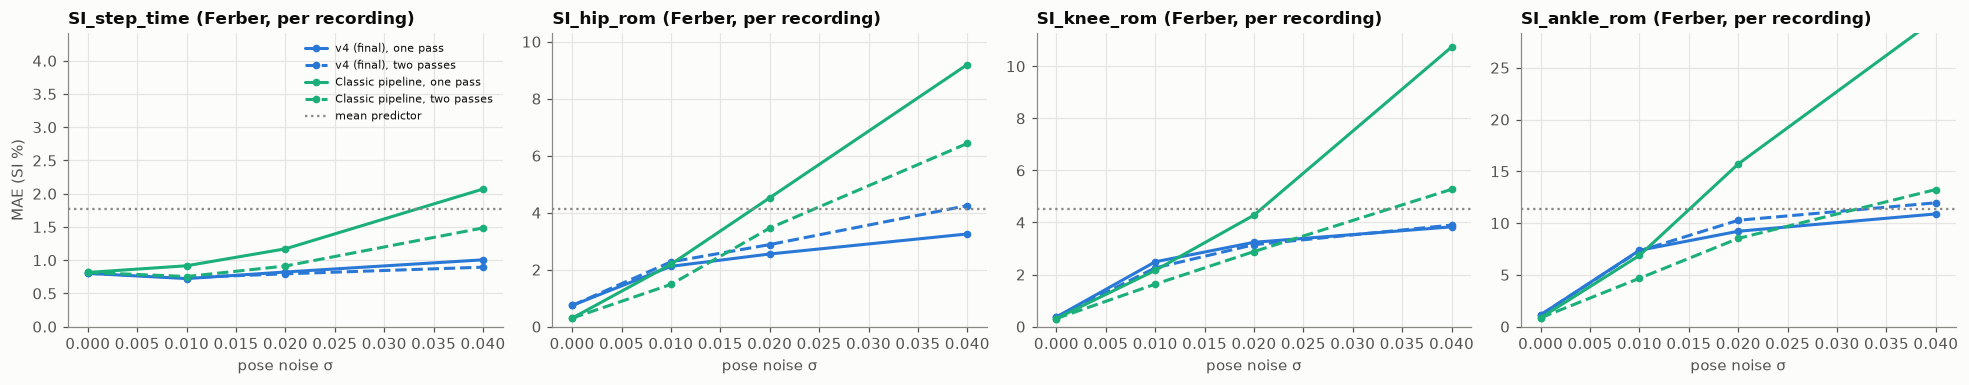

In [10]:
TRA = pd.concat([TR1, TR2])
fig, axs = plt.subplots(1, 4, figsize=(18, 3.6))
for a, t in zip(axs, ["SI_step_time", "SI_hip_rom", "SI_knee_rom", "SI_ankle_rom"]):
    for m in (RUN, "classic"):
        for prot, ls in (("one pass", "-"), ("two passes", "--")):
            g = TRA[(TRA.target == t) & (TRA.method == m) & (TRA.protocol == prot) & (TRA.dataset == "ferber")]
            g = g.sort_values("level")
            a.plot(g.level, g.mae, color=MCOL[m], ls=ls, marker="o", ms=4, label=f"{MLABEL[m]}, {prot}")
    mn = TR1[(TR1.target == t) & (TR1.method == "mean") & (TR1.dataset == "ferber")].mae.mean()
    a.axhline(mn, color=MUTED, ls=":", lw=1.5, label="mean predictor")
    a.set_title(f"{t} (Ferber, per recording)"); a.set_xlabel("pose noise σ"); a.set_ylim(0, 2.5 * mn)
axs[0].set_ylabel("MAE (SI %)"); axs[0].legend(fontsize=7)
fig.tight_layout(); save(fig, "06_recording_level"); plt.show()

## Ablation (σ = 0.02)
What each change buys, removing one step at a time: v4 → v3 (no synthetic asymmetry) → v2 (no gated geometry,
no local branch) → v2 without the L/R mirror; v4's own pooled heads (same network, no formula step); the first
model (v1) and v1 trained on clean mocap only. MAE first, then the SI slopes (1 = asymmetry at its true size).

In [11]:
abl = [RUN, "bigru_v3+derived", "bigru_v2+derived", "bigru_v2_noswap+derived", V4, PREV, "bigru_clean", "classic"]
A = (reg[(reg.level == 0.02) & reg.target.isin(core) & reg.method.isin(abl)]
     .pivot_table(index=["dataset", "target"], columns="method", values="mae").reindex(columns=abl))
A = A.reindex(pd.MultiIndex.from_product([DATASETS, core])).dropna(how="all")
A.columns = [MLABEL.get(c, c) for c in A.columns]
display(A.style.format("{:.3g}").highlight_min(axis=1, props="font-weight: bold"))
Sl = (reg[(reg.level == 0.02) & reg.target.isin(SI) & reg.method.isin(abl)]
      .pivot_table(index=["dataset", "target"], columns="method", values="slope").reindex(columns=abl))
Sl.columns = [MLABEL.get(c, c) for c in Sl.columns]
Sl.round(2)

v4 (final)  v3: no synthetic asymmetry  v2: no gated geometry / local branch  v2 without L/R mirror  v4 pooled heads (auxiliary)  v1: pooled regression heads  \
dataset target                                                                                                                                                                          
ferber  SI_ankle_rom          0.21                        0.18                                  0.13                   0.07                         0.26                         0.02   
        SI_hip_rom            0.62                        0.42                                  0.40                   0.26                         0.62                         0.21   
        SI_knee_rom           0.42                        0.38                                  0.29                   0.24                         0.55                         0.17   
        SI_stance_time        0.61                        0.61                                  0.55                   0.55                         0.39                         0.41   
        SI_step_time          0.86                        0.65                                  0.58                   0.53                         0.70                         0.51   
        SI_swing_time         0.60                        0.62                                  0.56                   0.55                         0.39                         0.38   
fukuchi SI_ankle_rom          0.17                        0.21                                  0.18                   0.16                         0.14                         0.01   
        SI_hip_rom            0.47                        0.43                                  0.33                   0.32                         0.37                         0.28   
        SI_knee_rom           0.59                        0.51                                  0.36                   0.21                         0.51                         0.09   
        SI_stance_time        0.20                        0.22                                  0.22                   0.27                         0.11                         0.23   
        SI_step_time          0.23                        0.17                                  0.13                   0.16                         0.16                         0.12   
        SI_swing_time         0.07                        0.08                                  0.08                   0.13                         0.04                         0.11   
toronto SI_ankle_rom          0.21                        0.17                                  0.17                   0.16                         0.23                         0.01   
        SI_hip_rom            0.75                        0.61                                  0.47                   0.26                         0.70                         0.43   
        SI_knee_rom           0.69                        0.59                                  0.67                   0.53                         0.67                         0.11   
        SI_stance_time        0.61                        0.66                                  0.52                   0.52                         0.34                         0.28   
        SI_step_time          0.73                        0.59                                  0.40                   0.42                         0.59                         0.33   
        SI_swing_time         0.61                        0.63                                  0.52                   0.56                         0.33                         0.30   

                        v1 trained on clean mocap  Classic pipeline  
dataset target                                                       
ferber  SI_ankle_rom                         0.00              0.66  
        SI_hip_rom                           0.00              0.87  
        SI_knee_rom                        

## Bland–Altman (v4, σ = 0.02)
Agreement with the gold labels per window; bias and 95 % limits of agreement pooled across datasets
(per-dataset numbers below).

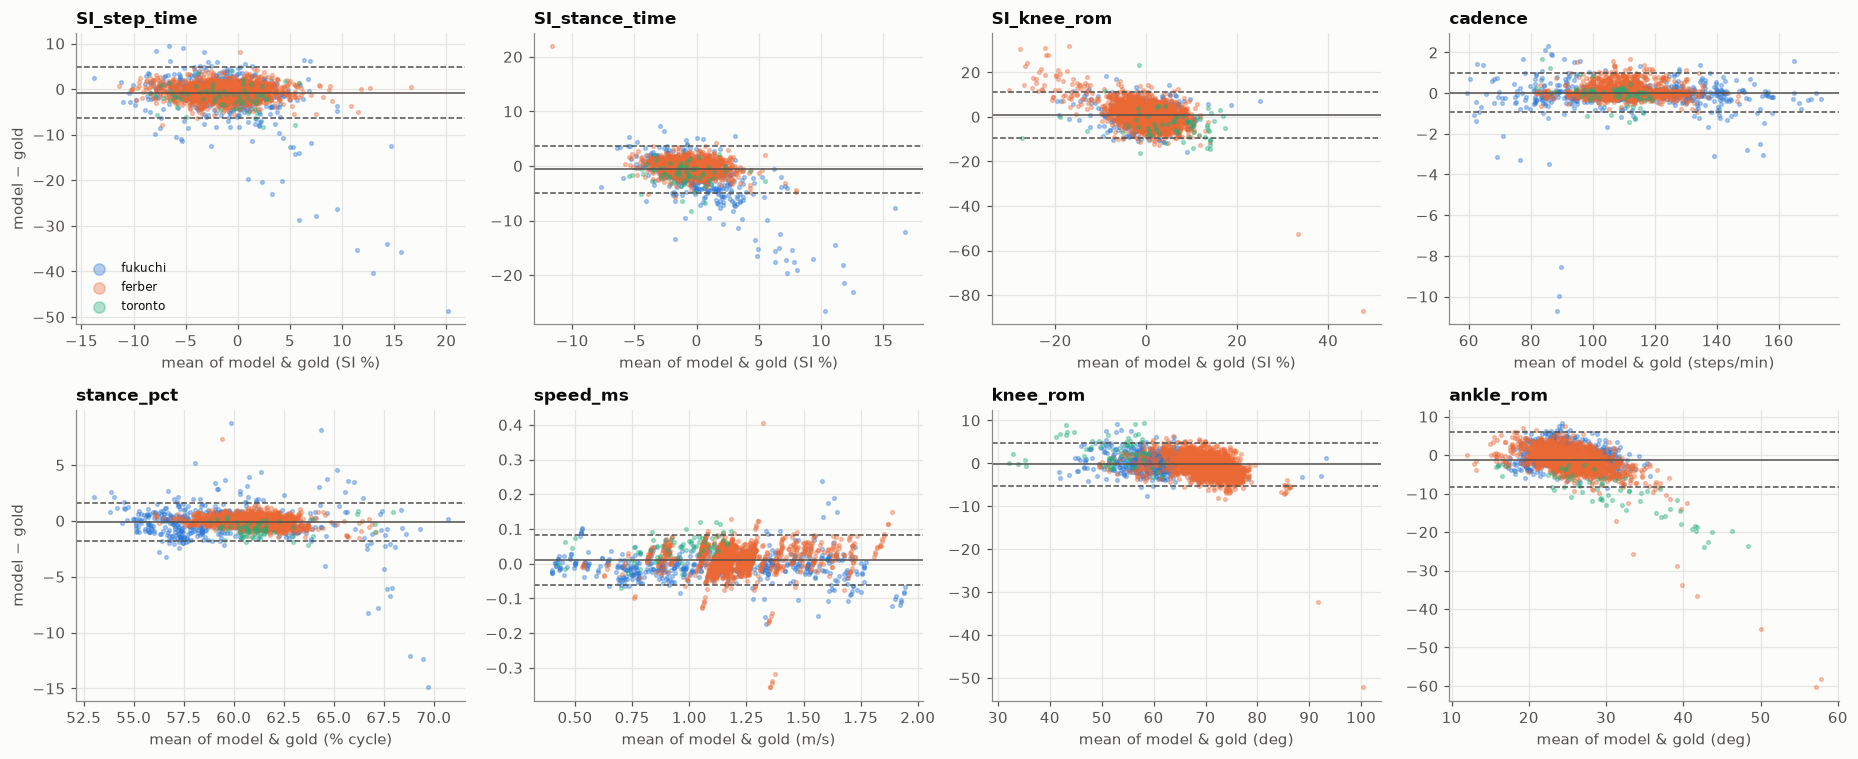

bias                     loa                
dataset        ferber fukuchi toronto  ferber fukuchi toronto
target                                                       
SI_knee_rom     1.092   0.518  -3.739  10.418   9.245  12.299
SI_stance_time -0.309  -1.948  -1.503   2.274   8.015   3.777
SI_step_time   -0.564  -1.616  -1.719   2.841  11.170   4.740
ankle_rom      -1.228  -0.039 -10.067   6.654   5.632  11.062
cadence         0.060  -0.106  -0.044   0.533   1.907   0.967
knee_rom       -0.501   0.311   2.640   4.903   4.464   5.923
speed_ms        0.013  -0.008   0.046   0.067   0.078   0.069
stance_pct     -0.057  -0.198  -0.740   0.853   3.417   1.254

In [12]:
ba = ["SI_step_time", "SI_stance_time", "SI_knee_rom", "cadence", "stance_pct", "speed_ms", "knee_rom", "ankle_rom"]
Q = P[(P.method == RUN) & (P.level == 0.02)]
fig, axs = plt.subplots(2, 4, figsize=(17, 7))
rows = []
for a, t in zip(axs.flat, ba):
    q = Q[[f"true_{t}", f"pred_{t}", "dataset"]].dropna()
    mean, diff = (q[f"true_{t}"] + q[f"pred_{t}"]) / 2, q[f"pred_{t}"] - q[f"true_{t}"]
    for ds in DATASETS:
        s = q.dataset == ds
        a.scatter(mean[s], diff[s], s=6, alpha=0.35, color=COL[ds], label=ds, rasterized=True)
        rows.append(dict(target=t, dataset=ds, n=int(s.sum()), bias=diff[s].mean(), loa=1.96 * diff[s].std()))
    b, sd = diff.mean(), diff.std()
    for y, ls in ((b, "-"), (b + 1.96 * sd, "--"), (b - 1.96 * sd, "--")):
        a.axhline(y, color=INK2, ls=ls, lw=1)
    a.set_title(t); a.set_xlabel(f"mean of model & gold ({UNIT.get(t, '')})")
axs[0, 0].set_ylabel("model − gold"); axs[1, 0].set_ylabel("model − gold"); axs[0, 0].legend(fontsize=8, markerscale=3)
fig.tight_layout(); save(fig, "06_bland_altman"); plt.show()
pd.DataFrame(rows).pivot(index="target", columns="dataset", values=["bias", "loa"]).round(3)

## Example: one held-out window at σ = 0.04
Noisy input, event probabilities with the gold events, and the predicted knee and ankle curves against the
clean mocap curves.

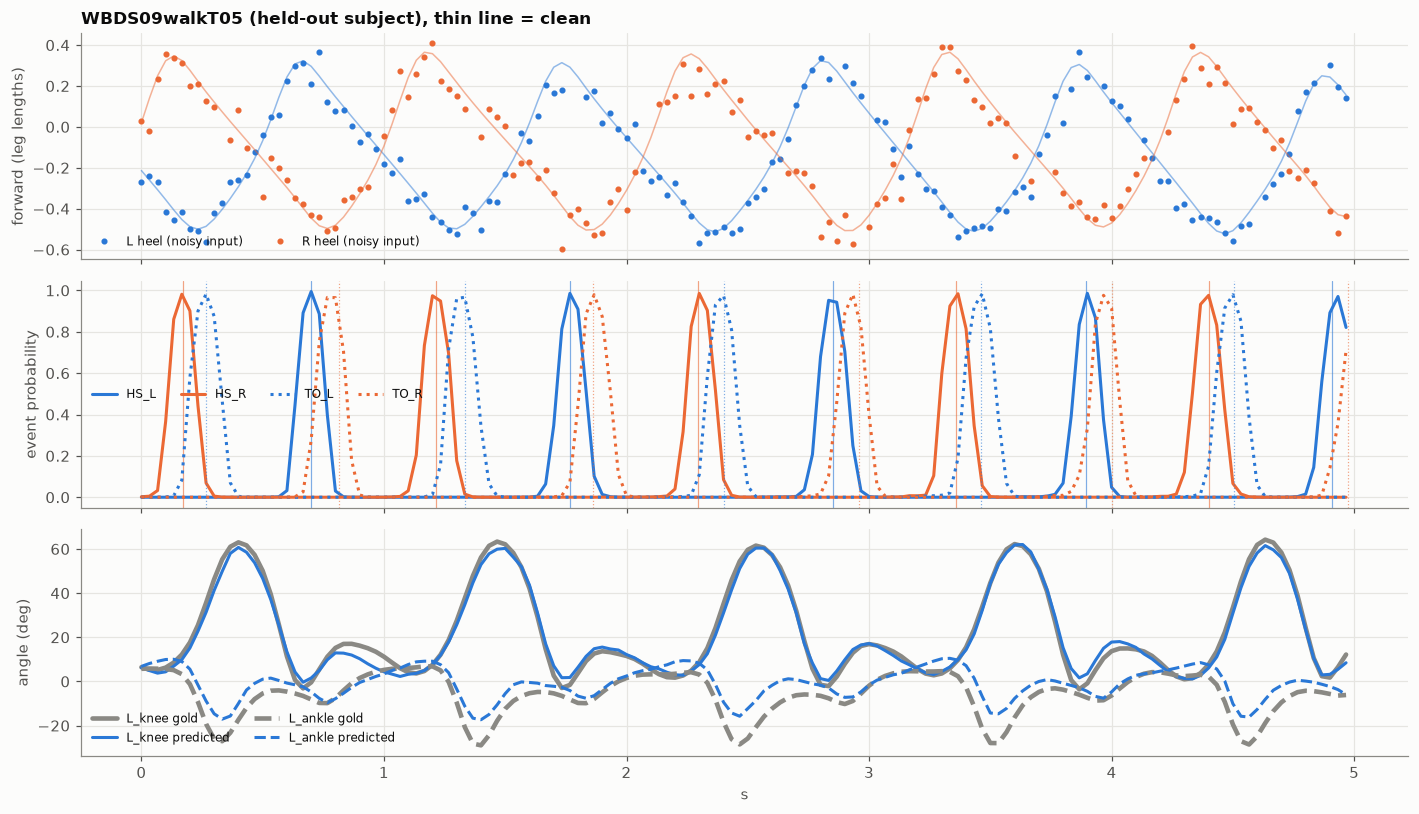

,cadence,stride_time,step_time,stance_time,swing_time,stance_pct,double_support,speed_ll,SI_step_time,SI_stance_time,SI_swing_time,SI_hip_rom,SI_knee_rom,SI_ankle_rom,hip_rom,knee_rom,ankle_rom,peak_knee_flex,stride_time_sd,stride_time_cv
v4 derived,113.614,1.056,0.528,0.618,0.439,58.478,0.179,1.457,-6.206,-2.630,4.132,0.392,-2.975,-1.497,43.226,61.059,25.575,62.185,0.023,2.149
v4 pooled,112.060,1.066,0.533,0.626,0.440,58.837,0.186,1.457,-4.391,-1.820,2.622,-2.661,-5.369,-10.305,44.083,62.763,26.500,63.263,0.012,1.116
gold,113.834,1.054,0.528,0.635,0.419,60.246,0.212,1.512,-5.678,-4.199,5.169,2.183,2.889,5.535,42.824,64.402,32.567,63.472,0.025,2.353


In [13]:
import torch, augment, gaitdata as G
from evaluate import load_model, run_model
from model import decode_events
data = G.load_all()["test"]
tr = next(t for t in data if t.ds == "fukuchi" and t.mode == "treadmill" and t.trial.endswith("T05"))
x, v = augment.apply(tr.pose[300:450], np.random.default_rng(3), augment.Noise.level(0.04))
m, cfg, norm = load_model(V4)
probs, y, ang = run_model(m, norm, [x], [v], cfg["features"])
t = np.arange(150) / 30
fig, axs = plt.subplots(3, 1, figsize=(13, 7.5), sharex=True)
for s, c in SIDE_COL.items():
    j = G.IN_JOINTS.index(f"{s}_heel")
    axs[0].plot(t, tr.pose[300:450, j, 0], color=c, lw=1, alpha=0.5)
    axs[0].plot(t, np.where(v[:, j] > 0, x[:, j, 0], np.nan), color=c, lw=0, marker="o", ms=3, label=f"{s} heel (noisy input)")
for k, name in enumerate(G.EVENTS):
    s, ls = name[-1], "-" if name.startswith("HS") else ":"
    axs[1].plot(t, probs[0][:, k], color=SIDE_COL[s], ls=ls, label=name)
    for e in tr.events[name] - 10:
        if 0 <= e <= 5: axs[1].axvline(e, color=SIDE_COL[s], lw=0.8, ls=ls, alpha=0.6)
for k, (n, ls) in enumerate((("L_knee", "-"), ("L_ankle", "--"))):
    i = G.ANG_NAMES.index(n)
    axs[2].plot(t, tr.ang[300:450, i], color=MUTED, ls=ls, lw=3, label=f"{n} gold")
    axs[2].plot(t, ang[0][:, i], color=SIDE_COL["L"], ls=ls, label=f"{n} predicted")
axs[0].set_ylabel("forward (leg lengths)"); axs[0].legend(fontsize=8, ncol=2)
axs[0].set_title(f"{tr.trial} (held-out subject), thin line = clean")
axs[1].set_ylabel("event probability"); axs[1].legend(fontsize=8, ncol=4)
axs[2].set_ylabel("angle (deg)"); axs[2].set_xlabel("s"); axs[2].legend(fontsize=8, ncol=2)
fig.tight_layout(); save(fig, "06_example_window"); plt.show()
yd = G.derive(decode_events(probs[0]), ang[0], 150, y[0][G.TI["speed_ll"]])
pd.DataFrame({"v4 derived": yd, "v4 pooled": y[0], "gold": G.window_labels(tr, 300, 450)},
             index=G.TARGET_NAMES).round(3).T

## Subgroups (age, sex)
v4 MAE at σ = 0.02 by subgroup, from the trial metadata. Toronto (all older adults) is the external check.

In [14]:
meta = all_trials()[["dataset", "trial", "age", "sex"]].copy()
meta["sex"] = meta.sex.astype(str).str.upper().str[0].map({"M": "male", "F": "female"})
meta["age_band"] = pd.cut(meta.age, [0, 40, 60, 120], labels=["<40", "40–60", "≥60"])
Q = P[(P.method == RUN) & (P.level == 0.02)].merge(meta, on=["dataset", "trial"], how="left")
rows = []
for by in ("age_band", "sex"):
    for (ds, grp), g in Q.groupby(["dataset", by], observed=True):
        for t in ["cadence", "stance_pct", "speed_ms", "SI_step_time", "knee_rom", "ankle_rom"]:
            d = g[[f"true_{t}", f"pred_{t}"]].dropna()
            rows.append(dict(group=by, dataset=ds, level=str(grp), target=t, n=len(d),
                             mae=(d.iloc[:, 1] - d.iloc[:, 0]).abs().mean()))
S = pd.DataFrame(rows)
S.pivot_table(index=["group", "dataset", "level"], columns="target", values="mae").round(3).join(
    S.groupby(["group", "dataset", "level"]).n.max())

SI_step_time  ankle_rom  cadence  knee_rom  speed_ms  stance_pct     n
group    dataset level                                                                         
age_band ferber  40–60          1.185      2.125    0.182     1.742     0.026       0.326  1181
                 <40            1.207      2.129    0.164     1.813     0.024       0.304   822
                 ≥60            1.277      2.608    0.189     1.785     0.028       0.458   190
         fukuchi 40–60          1.968      3.121    0.380     1.844     0.034       0.580    85
                 <40            3.003      2.441    0.489     1.470     0.026       1.014   253
                 ≥60            3.943      1.748    0.470     2.270     0.026       1.224   182
         toronto ≥60            2.322     10.067    0.313     3.129     0.051       0.837    66
sex      ferber  female         1.212      2.239    0.176     1.728     0.026       0.345  1254
                 male           1.187      2.073    0.177     1.831     0.025       0.308   939
         fukuchi female         3.236      2.642    0.588     1.855     0.034       1.144   236
                 male           3.111      2.034    0.362     1.775     0.022       0.910   284
         toronto female         1.984      9.855    0.287     3.319     0.052       0.903    56
                 male           4.214     11.254    0.458     2.067     0.043       0.463    10

## Findings

**Final model: `bigru_v4+derived`.** Events + gated angle curves → the label formulas, trained with pose noise,
the L/R mirror and synthetic asymmetry. Numbers are per 5 s window on held-out subjects unless stated; "slope" is
predicted vs gold (1 = an asymmetry is reported at its true size).

### What was fixed

| Problem in v1 | v1 | v4 | classic | mean |
|---|---|---|---|---|
| Step-time SI shrunk (slope, σ = 0.02): Ferber / Toronto | 0.51 / 0.33 | **0.86 / 0.73** | 0.92 / 1.04 | 0 |
| ↳ under-reporting of \|SI\| ≥ 7 (SI points, σ = 0.02) | −7.2 | **−3.2** | −2.2 | |
| Ankle-ROM SI, clean: MAE (slope), Ferber | 11.1 (0.03) | **0.77 (0.90)** | 1.04 (1.00) | 11.2 |
| Knee-ROM SI, σ = 0.02: MAE (slope), Toronto | 10.1 (0.11) | **5.7 (0.69)** | 7.6 (0.97) | 10.5 |
| Ankle ROM (°), clean: Ferber / Toronto | 2.9 / 13.8 | **0.19 / 1.8** | 0.27 / 0.71 | 3.2 / 11.0 |
| Knee ROM (°), σ = 0.02: Ferber / Toronto | 2.4 / 4.2 | **1.8 / 3.1** | 4.1 / 4.7 | 4.4 / 17.0 |
| Stance % (Toronto, σ = 0.02) | 1.35 | **0.84** | 1.13 | 1.43 |
| Stride-time CV (Toronto, σ = 0.02) | 0.65 | **0.43** | 1.04 | 0.98 |

Cadence (0.14–0.46 steps/min) and event timing (Ferber heel strike 2.5 ms clean, 3.5 ms at σ = 0.02, vs classic
8–11 ms) stay at or better than v1. A complete stride was decoded in every test window (0 % fallback to the pooled
heads).

### What each step did (ablation, σ = 0.02 unless stated)
1. **Formulas on dense heads (v2)**: removed most structural shrinkage of pooled regression.
2. **Gated geometric skip + local branch (v3)**: angle RMSE on clean pose 2–4° → 0.05–0.25° (better than the
   filtered classic curves); ROM and ROM-SI on clean or mildly noisy pose now match exact geometry.
3. **Diagnosis for v4**: v3's event errors were tiny (3–5 ms) but correlated with asymmetry. Adding random jitter of
   the same size to the gold events keeps the step-time SI slope at 1.0; the model's own events gave 0.6. It had
   learned "the legs are half a cycle apart" from a near-symmetric training set.
4. **Synthetic asymmetry (v4)**: step-time SI slope 0.65 → 0.86 (Ferber), 0.59 → 0.73 (Toronto); hip-/knee-ROM SI
   slopes up by 0.05–0.2, at about the same MAE.

### Per recording and the two-pass protocol (`evaluate_trials.py`)
Pooling all strides of a 30 s recording (one consistent noise draw per video) gives Ferber step-time SI MAE 0.82
with slope 0.89 at σ = 0.02 (mean predictor 1.77). Filming the patient **walking across and back**, and measuring
each leg from the pass where it is nearest the camera, mainly helps the unbiased-but-noisy classic ROM-SI
estimate. For the model it gives knee-ROM SI slope 0.69 → 0.73 (Toronto). Recommended capture protocol for the demo:
≥ 20 s of walking, both directions.

### Still limited (honest)
- **Stance- and swing-time SI** stay compressed (Ferber slope 0.61; |SI| ≥ 7 under-reported by ~10 points). The
  classic pipeline is compressed nearly as much in that bin, so part of it is label noise (toe-off labels are
  bias-corrected Zeni or GRF with known outliers). The phase-shift augmentation does not create stance asymmetry; a
  per-leg stance/swing time-warp augmentation is the next step.
- **Ankle-ROM SI under video-like noise (σ ≥ 0.02)** is near the mean predictor for every method, including classic
  and two passes. Jitter of ~1.6 cm on a ~20 cm heel–toe segment is ~6° per frame against a ~3° left/right
  difference, so the information is not in a single side view at that quality. The demo should show ankle symmetry
  only with a pose-quality check, or not at all.
- **Toronto ankle ROM under noise** (10.1° vs mean 11.0°, classic 8.1°) and **Toronto speed** (0.05 m/s vs v1's
  pooled 0.03) remain the weakest external-set numbers.
- **v4 vs v3 trade-off**: v3 is slightly better on stance-time SI and Toronto stance % (0.60 vs 0.84); v4 is better
  on every step-time and ROM symmetry slope. v4 is kept because reporting asymmetry at its true size was the goal.
- Everything here is still mocap-derived pose with simulated noise; real pose-estimator output has not been
  tested yet.
